# Real Estate Price Analysis.
## 1. Project Domain:- Estate Price Analysis

## *Objective :*
- Understand house price distribution.
- Identify important factors affecting prices.
- Estimate house prices using historical data.
- Handles messy data containing missing values,and present visual insights that support data-driven decision making for real-estate businesses,         buyers, and investors.
    
## 2. Dataset Information:

**Dataset:** King County House Sales (With Missing Values).

**Total Rcords:** `21613`

**Target Column:** `price`

## 3. Tools and Skills:
    1. Python.
    2. Pandas.
    3. Numpy.
    4. Data Cleaning & Preprocessing.
    5. Missing Value Treatment.
    6. Exploratory Data Analysis(EDA).
    7. Data Visulization (Matplotlib & Seaborn).

# Step 1- Data Loading and Understanding

In [4]:
import numpy as np
import pandas as pd

In [5]:
df=pd.read_csv('kc_house_data_NaN.csv',encoding='latin1')
df.head()
# print('Dataset Uploaded Succesfully')

,Unnamed: 0,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,0,7129300520,20141013T000000,221900.0,3.0,1.00,1180,5650,1.0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,1,6414100192,20141209T000000,538000.0,3.0,2.25,2570,7242,2.0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,2,5631500400,20150225T000000,180000.0,2.0,1.00,770,10000,1.0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,3,2487200875,20141209T000000,604000.0,4.0,3.00,1960,5000,1.0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,4,1954400510,20150218T000000,510000.0,3.0,2.00,1680,8080,1.0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [6]:
print('Total Rows:',df.shape[0])   #returns total number of rows
print('Total Columns:',df.shape[1])   #returns total number of columns

Total Rows: 21613
Total Columns: 22


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     21613 non-null  int64  
 1   id             21613 non-null  int64  
 2   date           21613 non-null  object 
 3   price          21613 non-null  float64
 4   bedrooms       21600 non-null  float64
 5   bathrooms      21603 non-null  float64
 6   sqft_living    21613 non-null  int64  
 7   sqft_lot       21613 non-null  int64  
 8   floors         21613 non-null  float64
 9   waterfront     21613 non-null  int64  
 10  view           21613 non-null  int64  
 11  condition      21613 non-null  int64  
 12  grade          21613 non-null  int64  
 13  sqft_above     21613 non-null  int64  
 14  sqft_basement  21613 non-null  int64  
 15  yr_built       21613 non-null  int64  
 16  yr_renovated   21613 non-null  int64  
 17  zipcode        21613 non-null  int64  
 18  lat   

In [8]:
#Basic Statistical Properties
df.describe()

,Unnamed: 0,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,21613.00000,2.161300e+04,2.161300e+04,21600.000000,21603.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,...,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,10806.00000,4.580302e+09,5.400881e+05,3.372870,2.115736,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,...,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,6239.28002,2.876566e+09,3.671272e+05,0.926657,0.768996,918.440897,4.142051e+04,0.539989,0.086517,0.766318,...,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,0.00000,1.000102e+06,7.500000e+04,1.000000,0.500000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,...,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,5403.00000,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,...,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,10806.00000,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,...,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,16209.00000,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,...,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,21612.00000,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,...,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


In [9]:
#What are column names

print(df.columns.to_list())

['Unnamed: 0', 'id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']


In [10]:
# What are the datatype of each columns

print(df.dtypes)

Unnamed: 0         int64
id                 int64
date              object
price            float64
bedrooms         float64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64
dtype: object


**Key Findings:**
    The dataset contains 21,613 residential property records and 22 columns, including house prices, property characteristics, location details, and       construction information.

# Step 2-  Data Cleaning and Preprocessing

- Removing Irrelevant columns.

In [11]:
df.drop(columns =['Unnamed: 0'], inplace= True)

- Identify missing values

In [12]:
missing_val=df.isnull().sum()
print(missing_val[missing_val > 0])

bedrooms     13
bathrooms    10
dtype: int64


- Missing Values:
  1. bedrooms
  2. bathrooms

### Missing Data Treatment

In [13]:
df['bedrooms'] = df['bedrooms'].fillna(df['bedrooms'].mean())
df['bathrooms'] = df['bathrooms'].fillna(df['bathrooms'].mean())

In [14]:
print('Missing values after cleaning:\n',df.isnull().sum().sum())

Missing values after cleaning:
 0


### Check duplicate Records

In [15]:
duplicates = df.duplicated().sum()
print("Total Duplicate Rows:", duplicates)

Total Duplicate Rows: 0


### Date Formatting

In [16]:
df['date']=pd.to_datetime(df['date'])

In [17]:
df['date'].dtypes

dtype('<M8[ns]')

### Key Findings

1. The original dataset contains 21,613 records and 22 columns.
2. A total of 23 missing values were identified:
   - Bedrooms: 13
   - Bathrooms: 10
3. Missing values were handled using mean method to preserve the dataset records.
4. Exact duplicate rows were checked.
5. The date column was converted into datetime format for time-based analysis.


# Step 3- Exploratory Data Analysis (EDA)

### Objective

The objective of EDA is to explore the housing dataset and identify factors associated with property prices.

- This analysis focuses on:

1. House price distribution
2. Bedroom and bathroom characteristics
3. Living area and lot size
4. Waterfront and property views

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

### Q.1 What is distribution of house prices?

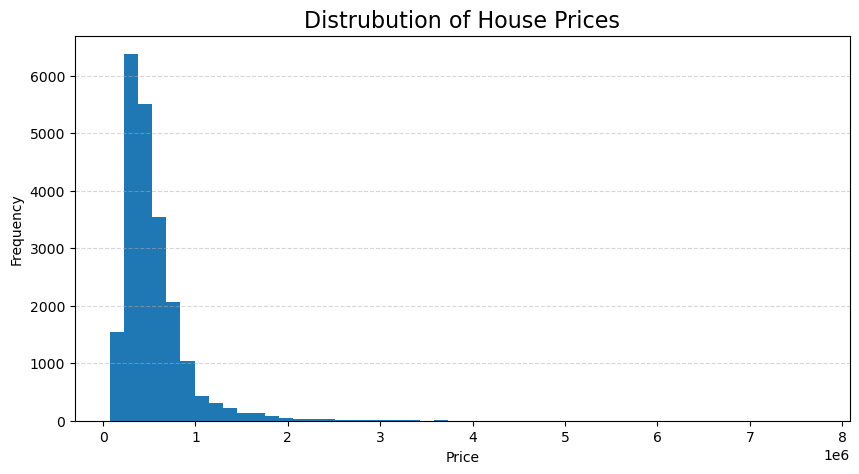

Mean Price: 540088.14
Median Price: 450000.0


In [19]:
plt.figure(figsize=(10,5))
plt.hist(df['price'], bins=50)
plt.title("Distrubution of House Prices",fontsize=16)
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.grid(True, axis='y',linestyle='--',alpha=0.5)
plt.show()

print("Mean Price:", round(df["price"].mean(), 2))
print("Median Price:", df["price"].median())

### Observation:
- The distribution of house prices is positively skewed (right-skewed).
- The average price is approximately 540,088, whereas the median is 450,000.

### Conclusion:
- Most properties are concentrated in the lower and middle price ranges, while relatively few properties have extremely high prices.

### Q.2 What is the distribution of bedrooms?

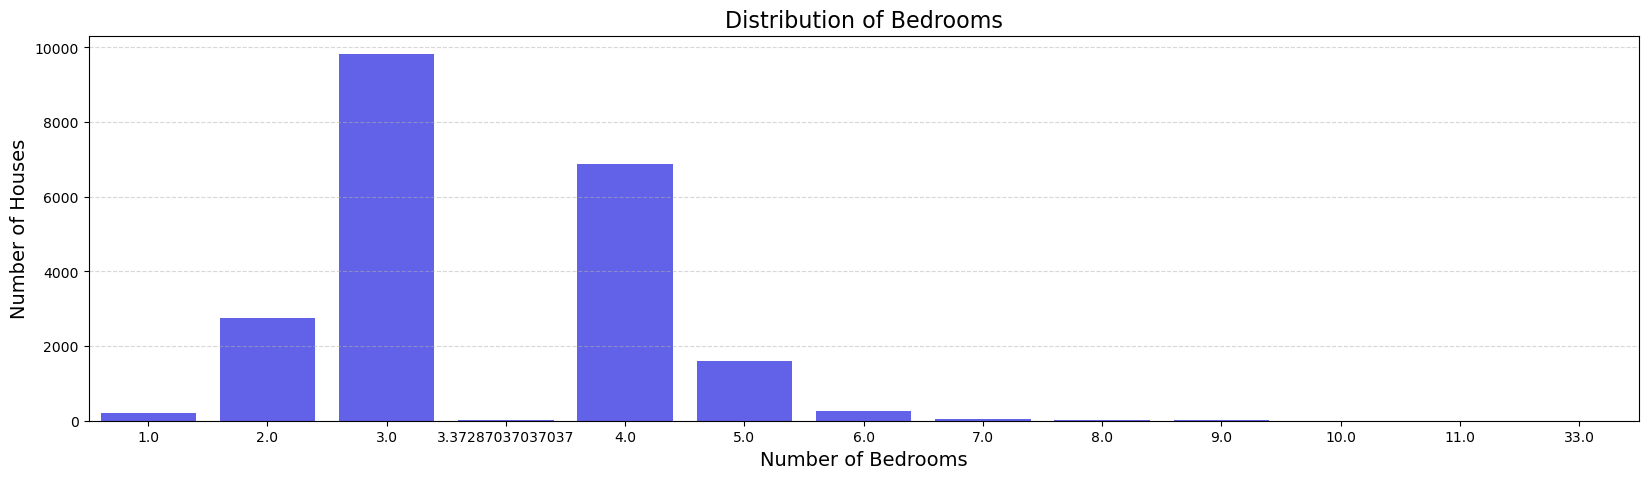

In [20]:
plt.figure(figsize=(20, 5))
sns.countplot(
    data=df,
    x="bedrooms",
    color="blue",
    alpha=0.7
)

plt.title("Distribution of Bedrooms",fontsize=16)
plt.xlabel("Number of Bedrooms",fontsize=14)
plt.ylabel("Number of Houses",fontsize=14)
plt.grid(True,axis='y',linestyle='--',alpha=0.5)
plt.show()


### Observation:
- The dataset is dominated by houses with three or four bedrooms.

### Conclusion:
- 3 bedroom and 4 bedroom properties represent a major segment of the King County housing market.

### Q.3 What is the distribution of bathrooms?

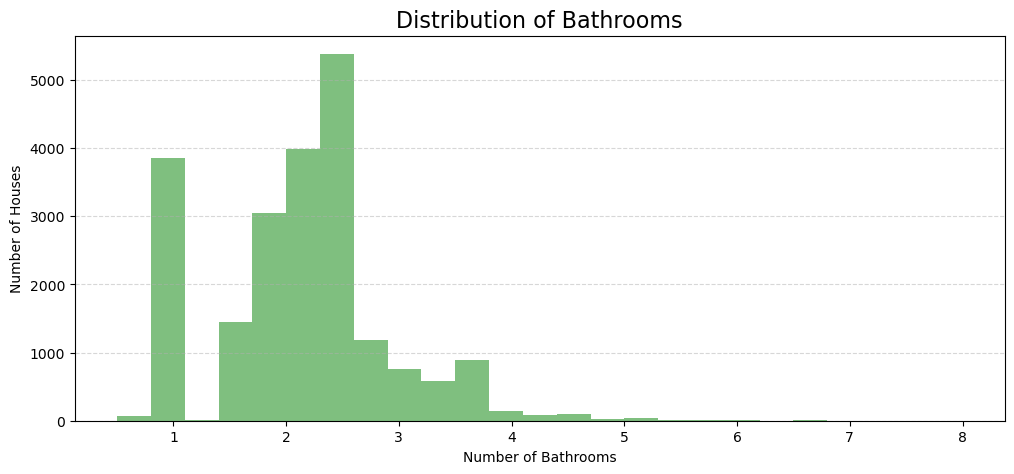

Correlation: 0.526


In [21]:
plt.figure(figsize=(12, 5))
plt.hist(
    data=df,
    x="bathrooms",
    bins=25,
    color="green",
    alpha=0.5
)
plt.title("Distribution of Bathrooms",fontsize=16)
plt.xlabel("Number of Bathrooms")
plt.ylabel("Number of Houses")
plt.grid(True,axis='y',linestyle='--',alpha=0.5)
plt.show()
print("Correlation:",round(df["bathrooms"].corr(df["price"]), 3))

### Observation:
- Bathroom count has a moderate positive correlation with house price.
  
### Conclusion:
- Properties with more bathrooms tend to be more expensive, although this relationship is partly associated with overall house size.

### Q.4 Does living area influence house price?

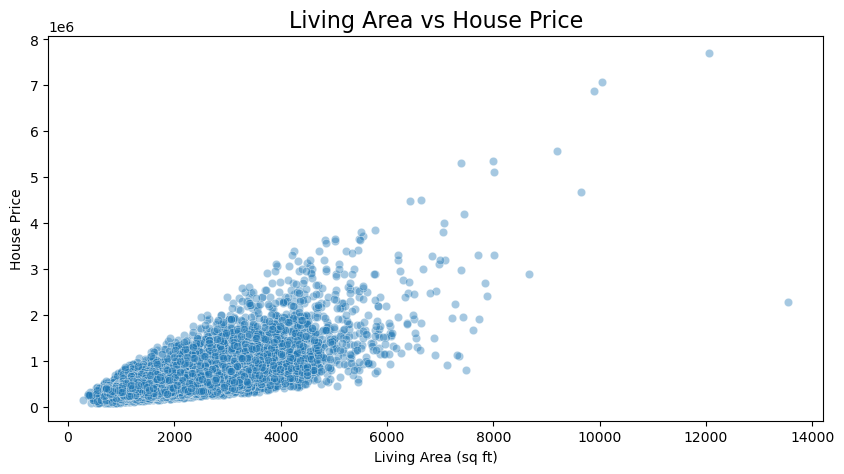

In [22]:
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df,
    x="sqft_living",
    y="price",
    alpha=0.4
)
plt.title("Living Area vs House Price",fontsize=16)
plt.xlabel("Living Area (sq ft)")
plt.ylabel("House Price")
plt.show()

### Observation:
- The correlation between living area and price is a strong positive relationship.

### Conclusion:
- Larger houses generally have higher selling prices.

### Q5. Does waterfront view increase price?

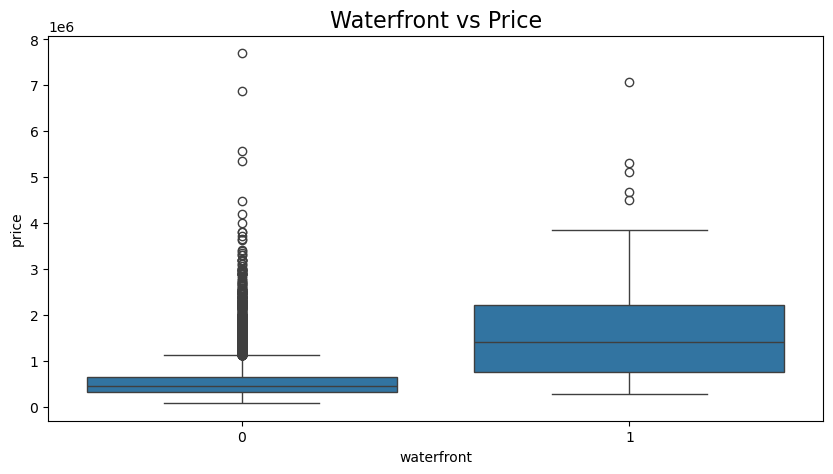

In [23]:
plt.figure(figsize=(10,5))
sns.boxplot(x='waterfront', y='price', data=df)
plt.title("Waterfront vs Price",fontsize=16)
plt.show()

### Observation:
- Waterfront properties have a higher average selling price than non-waterfront properties.
### Conclusion:
- Waterfront location is a premium feature.

### Q.6 How does the year a house was built affect its selling price?

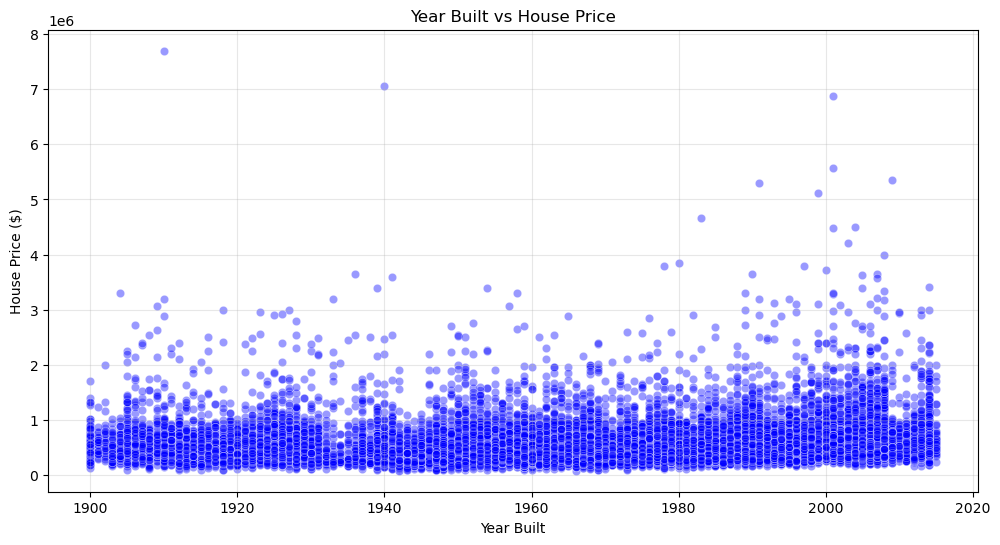

In [24]:
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=df,
    x="yr_built",
    y="price",
    color="blue",
    alpha=0.4
)
plt.title("Year Built vs House Price")
plt.xlabel("Year Built")
plt.ylabel("House Price ($)")
plt.grid(alpha=0.3)
plt.show()

### Observation:
- The relationship between the year a house was built and its selling price is relatively weak. Houses constructed in more recent years are not necessarily more expensive than older houses.

### Conclusion:
- The year of construction alone is not a strong indicator of house price.

### Q.7 How are different housing features related to each other?

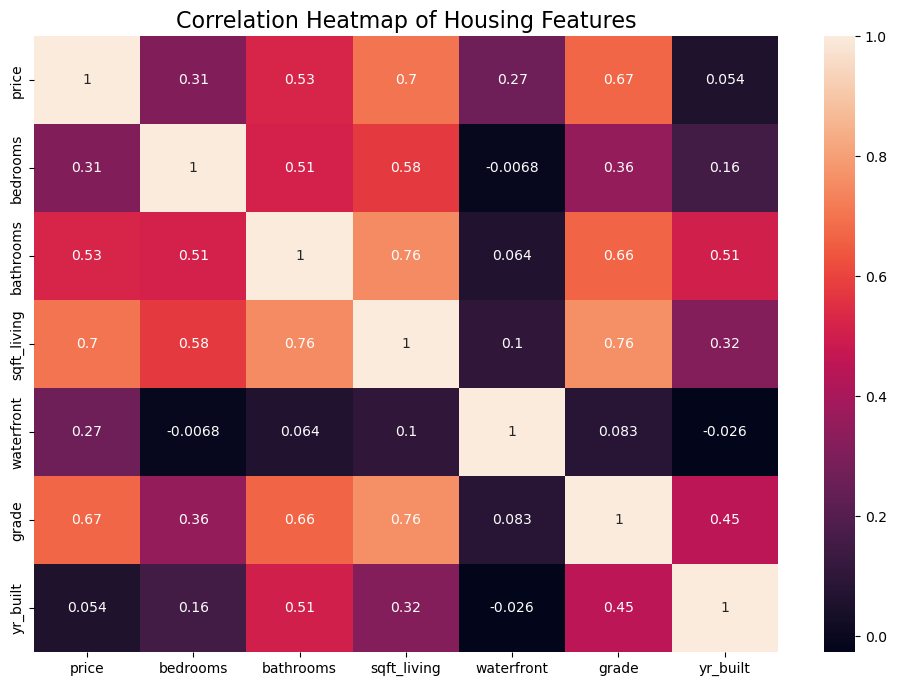

In [25]:
corr=df[["price","bedrooms","bathrooms","sqft_living","waterfront","grade","yr_built"]].corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr,annot=True)
plt.title("Correlation Heatmap of Housing Features",fontsize=16)
plt.show()

### Observation:
- The heatmap reveals positive relationships among living area, bathrooms, construction grade, and price.
### Conclusion:
- House prices can be predicted by living space.

# Step 4- Data Visualization Dashboard

## Key Findings

1. **Living area** has a strong positive correlation with house price (0.702).
2. Three-bedroom and four-bedroom properties are common in the dataset.
3. Bathroom count is moderately positively correlated with price.
4. Waterfront properties generally have higher average prices.
5. Year of construction alone does not strongly explain house prices.

## Final Conclusion:
- This project successfully transformed raw real-estate data with missing values into clean, structured, and insight-driven analytics.
- Overall, this analysis highlights important real estate pricing trends and provides valuable insights to help buyers, sellers, and investors make      informed decisions.